In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [ ]:
from sklearn.datasets import load_breast_cancer
import pandas as pd

# Load the dataset
data = load_breast_cancer(as_frame=True)


In [ ]:
# Convert it to a DataFrame
df = data.frame

# Show the first 5 rows
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:
df.shape

(569, 31)

In [ ]:
# Check for nulls
print("Missing Values:\n", df.isnull().sum())

Missing Values:
 mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64


In [ ]:
# Check for duplicates
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


In [ ]:
# Example: Check outliers for 'mean radius' using IQR
Q1 = df['mean radius'].quantile(0.25)
Q3 = df['mean radius'].quantile(0.75)
IQR = Q3 - Q1

# Outlier range
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['mean radius'] < lower) | (df['mean radius'] > upper)]
print(f"Number of outliers in 'mean radius': {outliers.shape[0]}")

Number of outliers in 'mean radius': 14


These 14 data points have a 'mean radius' either too small or too large compared to most of the other values.

In a boxplot, they appear as dots outside the "whiskers" (the normal range).

.shape → gives both rows and columns.

.shape[0] → gives only the number of rows (count of outliers).

.shape[1] → would give the number of columns.

# Visualize Outliers (Boxplot)

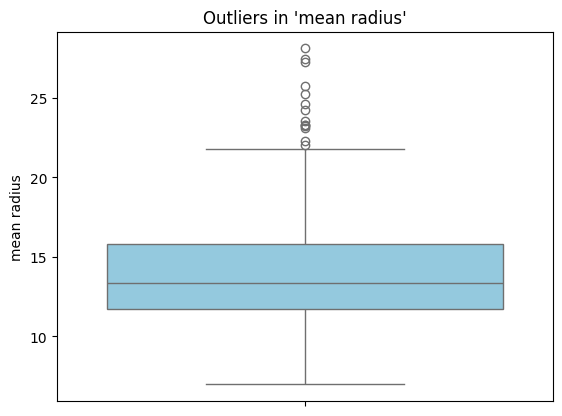

In [ ]:
sns.boxplot(y=df['mean radius'], color='skyblue')
plt.title("Outliers in 'mean radius'")
plt.show()

In [ ]:
df.shape

(569, 31)

In [ ]:
# Remove outliers in 'mean radius' only
df_clean = df[(df['mean radius'] >= lower) & (df['mean radius'] <= upper)]
print(f"New shape after removing outliers: {df_clean.shape}")

New shape after removing outliers: (555, 31)


🎯 Target: 'target' column (0 = malignant, 1 = benign)

# Split Features and Target

In [ ]:
X = df.drop('target', axis=1)
y = df['target']

In [ ]:
from sklearn.model_selection import train_test_split

# 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Logistic Regression Model

In [ ]:
from sklearn.linear_model import LogisticRegression

# Create model and fit
model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=10000)

# Evaluate the Model

In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Predict on test data
y_pred = model.predict(X_test)

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\n")
# Confusion matrix
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

print("\n")
# Classification report
print("Classification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.956140350877193


Confusion Matrix:
 [[39  4]
 [ 1 70]]


Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.91      0.94        43
           1       0.95      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



Class 0 means the person is diagnosed with cancer

Class 1 means the person is not diagnosed with cancer

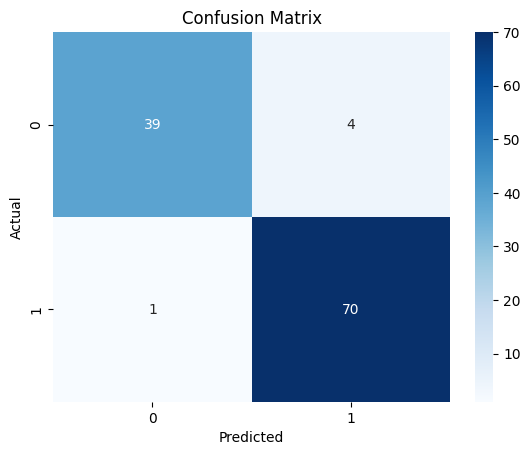

In [ ]:
# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['0', '1'], yticklabels=['0', '1'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

🔹 **Accuracy**: 0.9561 (≈ 96%)

This means the model correctly predicted whether the tumor was malignant or benign for 96% of the test cases.


🔹 **Confusion Matrix:**


Term	Meaning	Count


True Negative (TN)	Correctly predicted  	39  diagnosed with cancer

False Positive (FP)	Mistakenly predicted 4  diagnosed with cancer

False Negative (FN)	Mistakenly predicted  	1 not diagnosed with cancer

True Positive (TP)	Correctly predicted 70 not diagnosed with cancer


🔹 **Precision**:

Class 0 : 97%

Class 1 : 95%

Precision tells us when the model predicts a class, how often it's right.

🔹 **Recall**:

Class 0: 91%

Class 1: 99%

Recall tells us how well the model finds all positive cases.

🔹** F1-Score**:

Class 0: 0.94

Class 1: 0.97

In [ ]:
sample = [[17.99, 10.38, 122.8, 1001, 0.1184, 0.2776, 0.3001, 0.1471,
           0.2419, 0.07871, 1.095, 0.9053, 8.589, 153.4, 0.006399,
           0.04904, 0.05373, 0.01587, 0.03003, 0.006193, 25.38,
           17.33, 184.6, 2019, 0.1622, 0.6656, 0.7119, 0.2654,
           0.4601, 0.1189]]

prediction = model.predict(sample)
print("Prediction:", "Benign- not having" if prediction[0] == 1 else "Malignant- having disease")

Prediction: Malignant- having disease


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


In [ ]:
predictions = model.predict(X_test)

for i, pred in enumerate(predictions):
    print(f"Row {i}: Prediction:",
          "Benign - not having disease" if pred == 1 else "Malignant - having disease")


Row 0: Prediction: Benign - not having disease
Row 1: Prediction: Malignant - having disease
Row 2: Prediction: Malignant - having disease
Row 3: Prediction: Benign - not having disease
Row 4: Prediction: Benign - not having disease
Row 5: Prediction: Malignant - having disease
Row 6: Prediction: Malignant - having disease
Row 7: Prediction: Malignant - having disease
Row 8: Prediction: Benign - not having disease
Row 9: Prediction: Benign - not having disease
Row 10: Prediction: Benign - not having disease
Row 11: Prediction: Malignant - having disease
Row 12: Prediction: Benign - not having disease
Row 13: Prediction: Malignant - having disease
Row 14: Prediction: Benign - not having disease
Row 15: Prediction: Malignant - having disease
Row 16: Prediction: Benign - not having disease
Row 17: Prediction: Benign - not having disease
Row 18: Prediction: Benign - not having disease
Row 19: Prediction: Malignant - having disease
Row 20: Prediction: Benign - not having disease
Row 21: Pre

In [ ]:
# Select the row you want (e.g., row 5)
row = X_test.iloc[5].values  # convert to array

# Make prediction
prediction = model.predict([row])

# Print result
print("Prediction:", "Benign - not having disease" if prediction[0] == 1 else "Malignant - having disease")


Prediction: Malignant - having disease


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(
